# UGBRNet — Fixed Kaggle CUDA Notebook
## Uncertainty-Guided Multi-Scale Boundary Refinement Network for Small Camouflaged Object Detection

This corrected version uses **explicit dataset folders** instead of recursive guessing. In particular:
- **COD10K:** uses `GT_Object` (binary object masks), not `GT_Instance`; excludes `NonCAM` images.
- **CAMO:** uses `Images/Train` and `Images/Test`, never `Overlaid_Mask`. GT masks are matched by filename stem from `GT`.
- **CHAMELEON / NC4K:** optional benchmark-only datasets are safely detected if attached.
- Masks are binarized as **non-zero = foreground** after nearest-neighbor resizing.
- CUDA + AMP training, uncertainty-guided boundary refinement, small-object evaluation, pixel-level confusion matrices, qualitative outputs, and CSV export are included.

**Important:** Run the dataset sanity-check cell before training. Do not train unless the overlays align.


In [1]:
# Cell 1 — Environment / CUDA check
import os, gc, random, math, time, warnings
from pathlib import Path
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision.models import resnet34, ResNet34_Weights
from torchvision.transforms import functional as TF
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = True

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch:', torch.__version__)
print('CUDA available:', torch.cuda.is_available())
print('Device:', device)
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
    print('CUDA:', torch.version.cuda)

PyTorch: 2.11.0+cu128
CUDA available: True
Device: cuda
GPU: Tesla T4
CUDA: 12.8


In [2]:
# Cell 2 — Configuration
CFG = {
    'image_size': 352,
    'batch_size': 8,
    'epochs': 30,
    'lr': 2e-4,
    'weight_decay': 1e-4,
    'num_workers': 2,
    'threshold': 0.5,
    'small_object_ratio': 0.10,
    'val_fraction': 0.10,
    'train_limit': None,  # e.g. 500 for a quick smoke test
    'val_limit': None,
}
print(CFG)


{'image_size': 352, 'batch_size': 8, 'epochs': 30, 'lr': 0.0002, 'weight_decay': 0.0001, 'num_workers': 2, 'threshold': 0.5, 'small_object_ratio': 0.1, 'val_fraction': 0.1, 'train_limit': None, 'val_limit': None}


In [3]:
# Cell 3 — Inspect Kaggle inputs and locate the two required datasets
INPUT = Path('/kaggle/input')
assert INPUT.exists(), 'This notebook is intended for Kaggle. Add the datasets under Add Input.'

def find_dir_named(name):
    hits=[p for p in INPUT.rglob(name) if p.is_dir()]
    return hits[0] if hits else None

COD_ROOT = find_dir_named('COD10K-v3')
CAMO_ROOT = find_dir_named('CAMO-V.1.0-CVIU2019')

print('COD10K root:', COD_ROOT)
print('CAMO root  :', CAMO_ROOT)
assert COD_ROOT is not None, 'COD10K-v3 not found. Add the COD10K Kaggle dataset.'
assert CAMO_ROOT is not None, 'CAMO-V.1.0-CVIU2019 not found. Add the CAMO Kaggle dataset.'

print('\nCOD10K folders:')
for split in ['Train','Test']:
    p=COD_ROOT/split
    print(split, [x.name for x in p.iterdir() if x.is_dir()])
print('CAMO folders:', [x.name for x in CAMO_ROOT.iterdir() if x.is_dir()])


COD10K root: /kaggle/input/datasets/ivanomelchenkoim11/cod10k-dataset/COD10K-v3
CAMO root  : /kaggle/input/datasets/ivanomelchenkoim11/camo-dataset/CAMO-V.1.0-CVIU2019

COD10K folders:
Train ['GT_Edge', 'GT_Instance', 'GT_Object', 'Image']
Test ['GT_Edge', 'GT_Instance', 'GT_Object', 'Image']
CAMO folders: ['GT', 'Images', 'Overlaid_Mask']


In [4]:
# Cell 4 — Correct, explicit image/mask pairing
IMG_EXTS={'.jpg','.jpeg','.png','.bmp','.webp'}

def file_map(folder):
    return {p.stem:p for p in Path(folder).iterdir() if p.is_file() and p.suffix.lower() in IMG_EXTS}

def pair_exact(image_dir, mask_dir, cam_only=False):
    image_dir,mask_dir=Path(image_dir),Path(mask_dir)
    assert image_dir.exists(), f'Missing image folder: {image_dir}'
    assert mask_dir.exists(), f'Missing mask folder: {mask_dir}'
    ims=file_map(image_dir); gts=file_map(mask_dir)
    names=sorted(set(ims)&set(gts))
    if cam_only:
        names=[n for n in names if 'noncam' not in n.lower()]
    return [(ims[n],gts[n]) for n in names]

# COD10K: GT_Object is the correct binary object mask. GT_Instance is NOT used.
cod_train_all=pair_exact(COD_ROOT/'Train'/'Image', COD_ROOT/'Train'/'GT_Object', cam_only=True)
cod_test=pair_exact(COD_ROOT/'Test'/'Image', COD_ROOT/'Test'/'GT_Object', cam_only=True)

# CAMO: original RGB images only. Never use Overlaid_Mask.
camo_gt=file_map(CAMO_ROOT/'GT')
def pair_camo(split):
    ims=file_map(CAMO_ROOT/'Images'/split)
    names=sorted(set(ims)&set(camo_gt))
    return [(ims[n],camo_gt[n]) for n in names]

camo_train_all=pair_camo('Train')
camo_test=pair_camo('Test')

print('COD10K train:',len(cod_train_all),'test:',len(cod_test))
print('CAMO   train:',len(camo_train_all),'test:',len(camo_test))
print('COD example:',cod_train_all[0] if cod_train_all else None)
print('CAMO example:',camo_train_all[0] if camo_train_all else None)
assert cod_train_all and cod_test, 'COD10K pairing failed.'
assert camo_train_all and camo_test, 'CAMO pairing failed.'
assert all('overlaid_mask' not in str(a).lower() for a,_ in camo_train_all+camo_test)


COD10K train: 3040 test: 2026
CAMO   train: 1000 test: 250
COD example: (PosixPath('/kaggle/input/datasets/ivanomelchenkoim11/cod10k-dataset/COD10K-v3/Train/Image/COD10K-CAM-1-Aquatic-1-BatFish-1.jpg'), PosixPath('/kaggle/input/datasets/ivanomelchenkoim11/cod10k-dataset/COD10K-v3/Train/GT_Object/COD10K-CAM-1-Aquatic-1-BatFish-1.png'))
CAMO example: (PosixPath('/kaggle/input/datasets/ivanomelchenkoim11/camo-dataset/CAMO-V.1.0-CVIU2019/Images/Train/camourflage_00001.jpg'), PosixPath('/kaggle/input/datasets/ivanomelchenkoim11/camo-dataset/CAMO-V.1.0-CVIU2019/GT/camourflage_00001.png'))


In [8]:
# Cell 5 — Train/validation split + optional CHAMELEON/NC4K test discovery
def split_train_val(pairs, frac=0.10, seed=42):
    p=list(pairs); random.Random(seed).shuffle(p)
    nv=max(1,int(len(p)*frac))
    return p[nv:],p[:nv]

cod_tr,cod_val=split_train_val(cod_train_all,CFG['val_fraction'],SEED)
camo_tr,camo_val=split_train_val(camo_train_all,CFG['val_fraction'],SEED+1)
train_pairs=cod_tr+camo_tr
val_pairs=cod_val+camo_val
random.Random(SEED).shuffle(train_pairs)
random.Random(SEED).shuffle(val_pairs)

# Safe optional benchmark finder: requires separate image and GT/mask folders and rejects overlay folders.
def optional_benchmark(keyword):
    candidates=[p for p in INPUT.rglob('*') if p.is_dir() and keyword.lower() in p.name.lower()]
    for root in candidates:
        dirs=[d for d in root.rglob('*') if d.is_dir() and 'overlay' not in str(d).lower()]
        image_dirs=[d for d in dirs if d.name.lower() in {'image','images','imgs','img'}]
        mask_dirs=[d for d in dirs if d.name.lower() in {'gt','mask','masks','groundtruth','ground_truth'}]
        for imd in image_dirs:
            for msk in mask_dirs:
                try:
                    ps=pair_exact(imd,msk,cam_only=False)
                    if ps: return ps
                except Exception: pass
    return []

chameleon_test=optional_benchmark('CHAMELEON')
nc4k_test=optional_benchmark('NC4K')
benchmarks={'COD10K':cod_test,'CAMO':camo_test}
if chameleon_test: benchmarks['CHAMELEON']=chameleon_test
if nc4k_test: benchmarks['NC4K']=nc4k_test

if CFG['train_limit']: train_pairs=train_pairs[:CFG['train_limit']]
if CFG['val_limit']: val_pairs=val_pairs[:CFG['val_limit']]
print('Combined train:',len(train_pairs),'validation:',len(val_pairs))
for k,v in benchmarks.items(): print('Test',k,len(v))
if not chameleon_test: print('CHAMELEON not attached/detected — optional test benchmark skipped.')
if not nc4k_test: print('NC4K not attached/detected — optional test benchmark skipped.')


Combined train: 3636 validation: 404
Test COD10K 2026
Test CAMO 250
CHAMELEON not attached/detected — optional test benchmark skipped.
NC4K not attached/detected — optional test benchmark skipped.


In [6]:
# Cell 6 — Dataset and DataLoaders (fixed mask handling)
class CODDataset(Dataset):
    def __init__(self,pairs,size=352,augment=False):
        self.pairs=list(pairs); self.size=size; self.augment=augment
    def __len__(self): return len(self.pairs)
    def __getitem__(self,i):
        ip,mp=self.pairs[i]
        img=Image.open(ip).convert('RGB')
        mask=Image.open(mp).convert('L')
        img=TF.resize(img,[self.size,self.size],antialias=True)
        mask=TF.resize(mask,[self.size,self.size],interpolation=TF.InterpolationMode.NEAREST)
        if self.augment:
            if random.random()<.5: img=TF.hflip(img); mask=TF.hflip(mask)
            if random.random()<.15: img=TF.vflip(img); mask=TF.vflip(mask)
            if random.random()<.25:
                ang=random.uniform(-10,10)
                img=TF.rotate(img,ang)
                mask=TF.rotate(mask,ang,interpolation=TF.InterpolationMode.NEAREST)
            if random.random()<.25: img=TF.adjust_brightness(img,random.uniform(.85,1.15))
        img=TF.normalize(TF.to_tensor(img),[0.485,0.456,0.406],[0.229,0.224,0.225])
        # IMPORTANT: any non-zero label is foreground; works for 0/255 and indexed masks.
        mask=(TF.pil_to_tensor(mask).float()>0).float()
        return img,mask,str(ip)

def loader(pairs,augment=False,shuffle=False,bs=None):
    return DataLoader(CODDataset(pairs,CFG['image_size'],augment),batch_size=bs or CFG['batch_size'],
                      shuffle=shuffle,num_workers=CFG['num_workers'],pin_memory=torch.cuda.is_available(),drop_last=False)

train_loader=loader(train_pairs,True,True)
val_loader=loader(val_pairs,False,False)
print('Train batches:',len(train_loader),'Val batches:',len(val_loader))


Train batches: 455 Val batches: 51



 COD10K TRAIN — 3040 pairs
COD10K-CAM-3-Flying-62-Mantis-4383.jpg | size (880, 1024) mask (880, 1024) | values [  0 255] | foreground 11.05%
COD10K-CAM-1-Aquatic-18-StarFish-1155.jpg | size (800, 531) mask (800, 531) | values [  0 255] | foreground 1.29%
COD10K-CAM-1-Aquatic-13-Pipefish-601.jpg | size (1024, 948) mask (1024, 948) | values [  0 255] | foreground 8.67%
COD10K-CAM-5-Other-69-Other-5064.jpg | size (1280, 852) mask (1280, 852) | values [  0 255] | foreground 13.67%
COD10K-CAM-2-Terrestrial-30-Duck-1867.jpg | size (800, 599) mask (800, 599) | values [  0 255] | foreground 0.90%


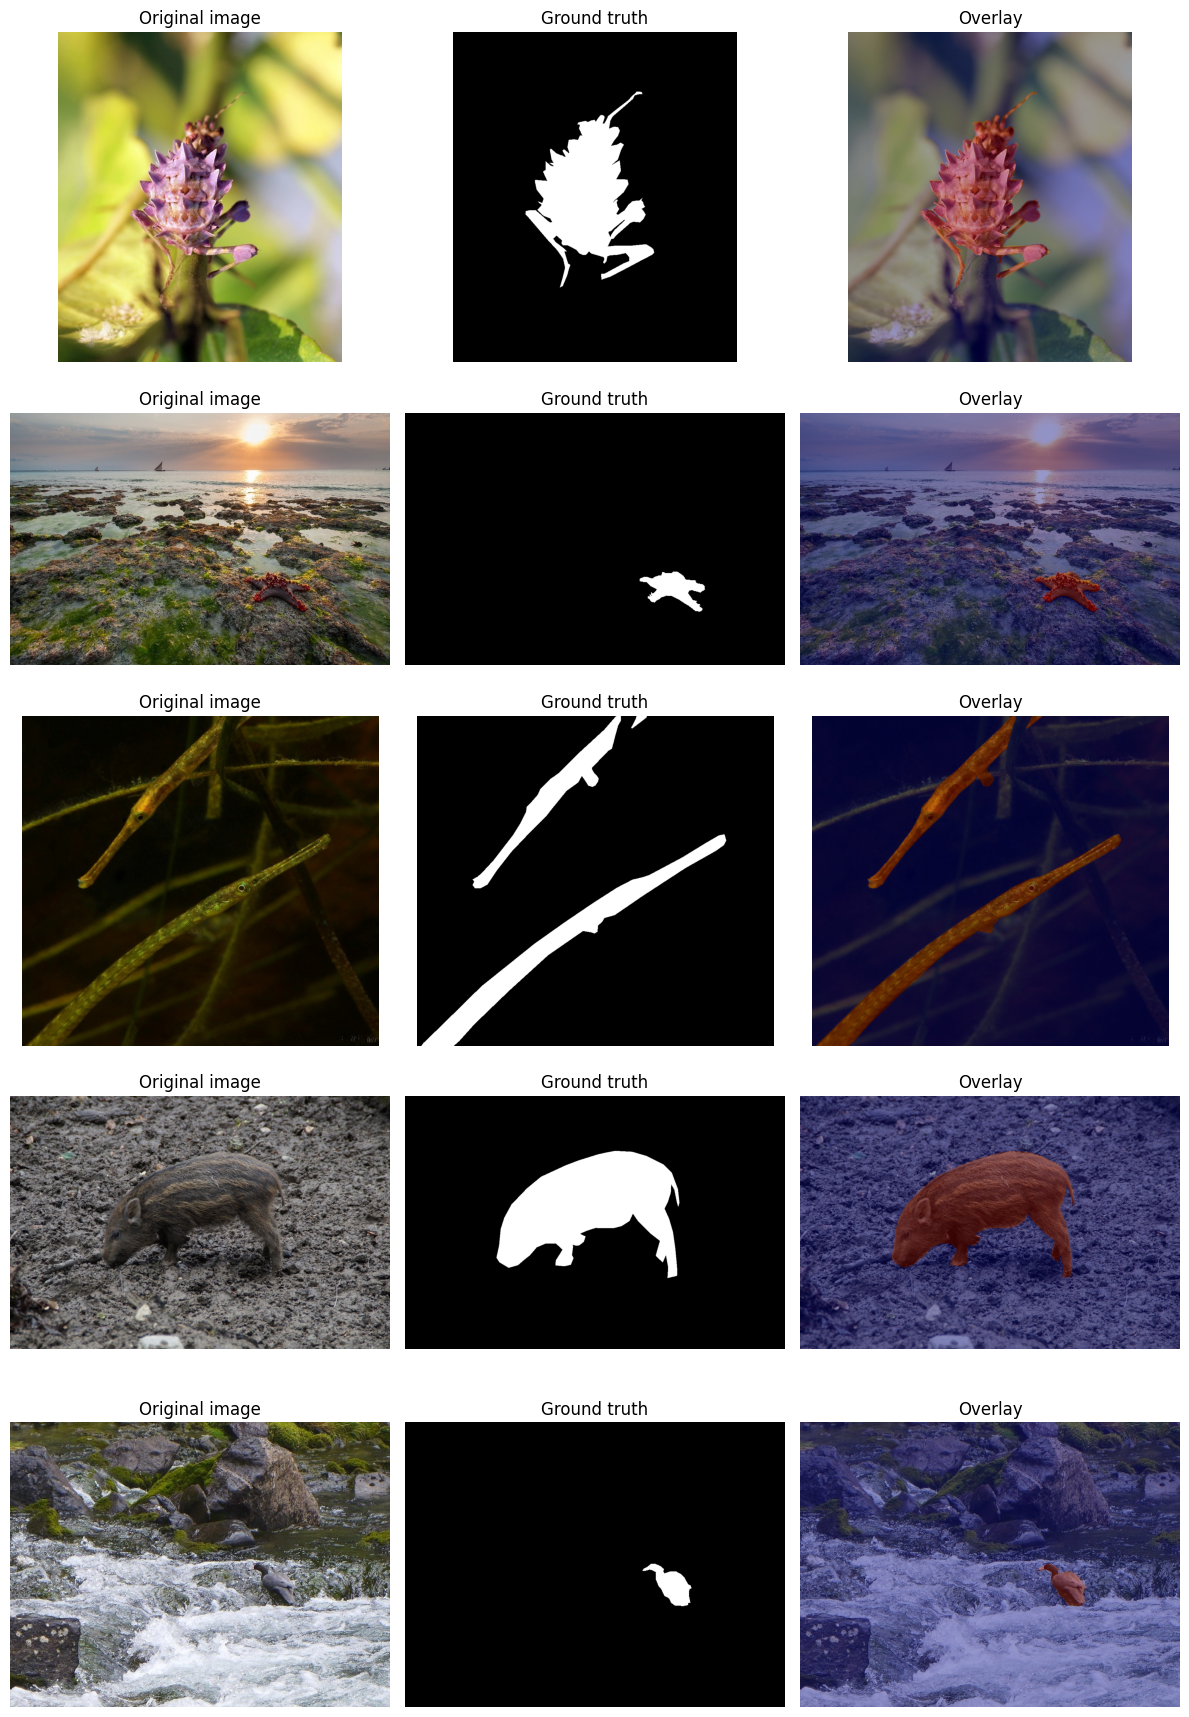


 CAMO TRAIN — 1000 pairs
camourflage_00760.jpg | size (259, 195) mask (259, 195) | values [  0 255] | foreground 16.06%
camourflage_00134.jpg | size (530, 392) mask (530, 392) | values [  0 255] | foreground 5.27%
camourflage_00028.jpg | size (576, 460) mask (576, 460) | values [  0 255] | foreground 4.20%
camourflage_00880.jpg | size (400, 285) mask (400, 285) | values [  0 255] | foreground 11.32%
camourflage_00334.jpg | size (233, 217) mask (233, 217) | values [  0 255] | foreground 4.07%


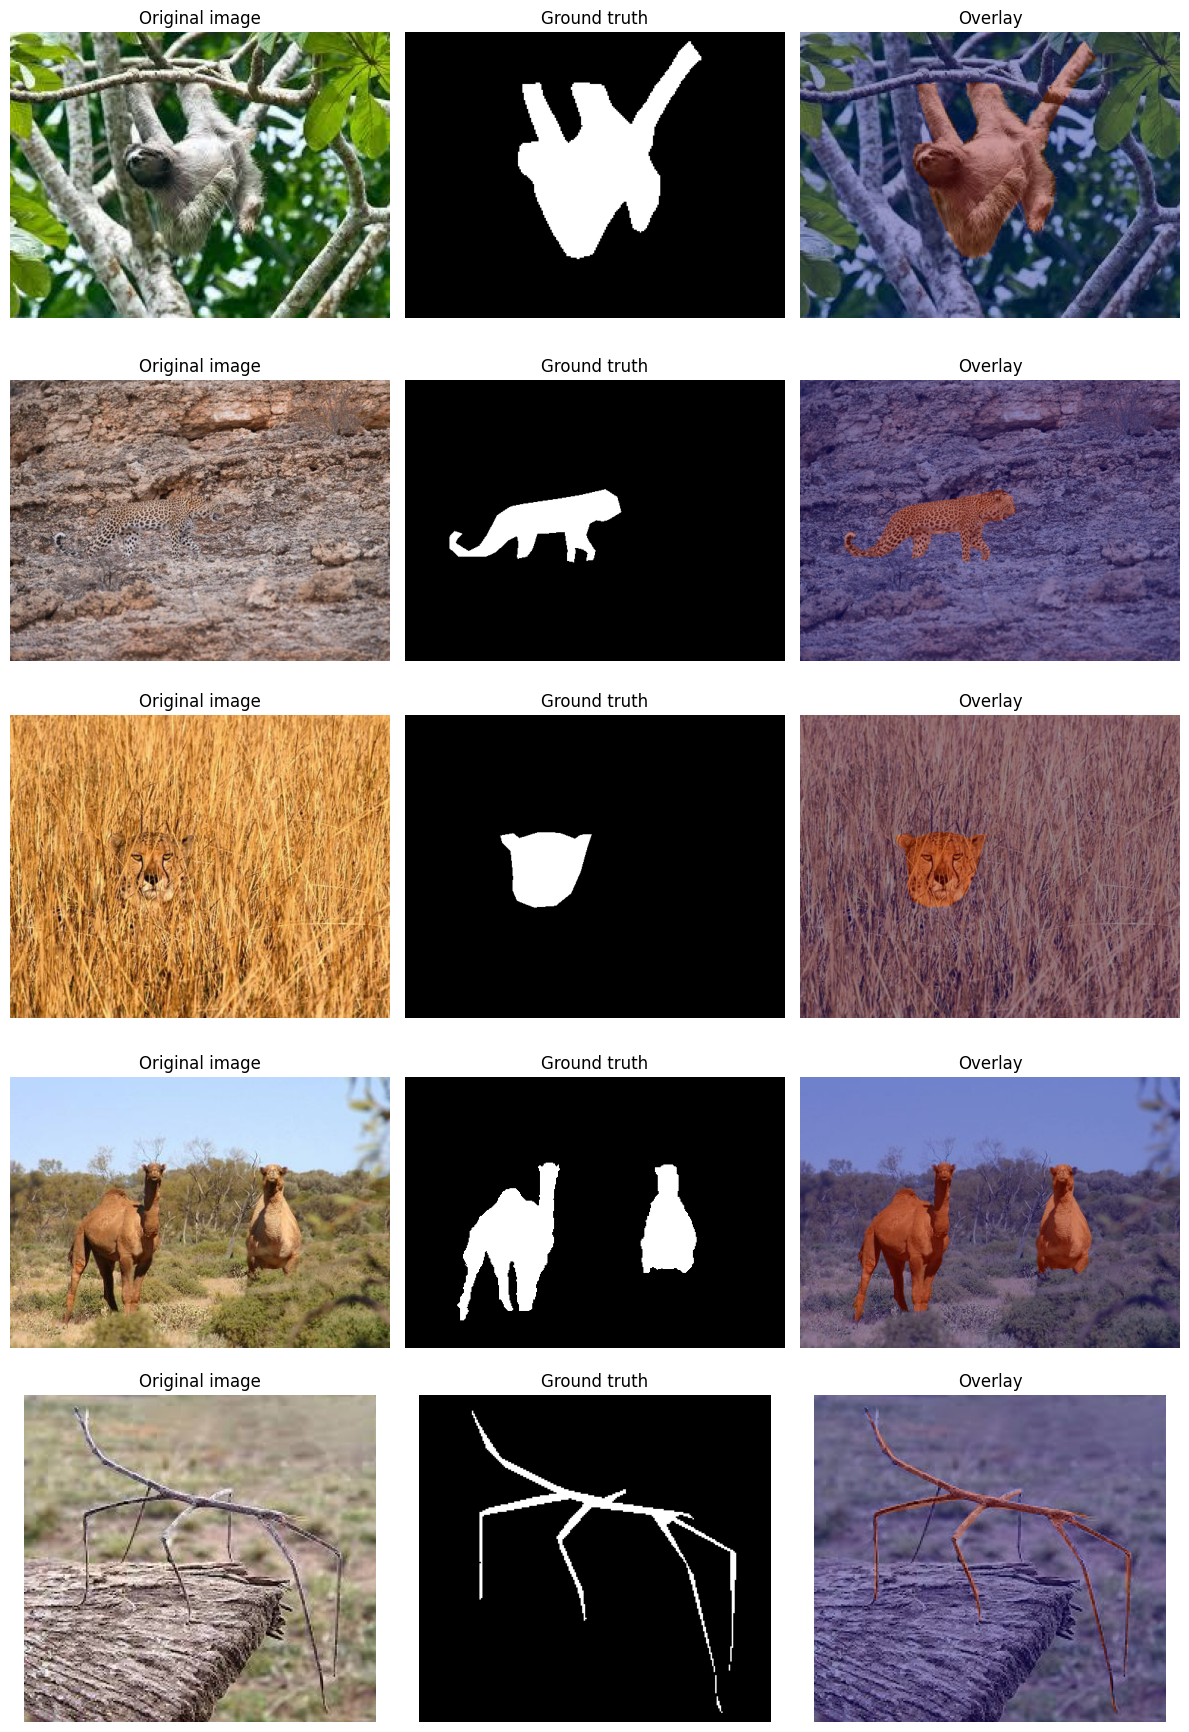

STOP HERE if any mask does not align with its object.


In [7]:
# Cell 7 — MANDATORY dataset sanity check
def sanity_check(pairs,name,n=5):
    picks=random.Random(SEED).sample(list(pairs),min(n,len(pairs)))
    fig,axs=plt.subplots(len(picks),3,figsize=(12,3.5*len(picks)))
    if len(picks)==1: axs=np.expand_dims(axs,0)
    print('\n',name,'—',len(pairs),'pairs')
    for i,(ip,mp) in enumerate(picks):
        img=Image.open(ip).convert('RGB'); raw=np.array(Image.open(mp).convert('L'))
        fg=raw>0
        print(Path(ip).name,'| size',img.size,'mask',Image.open(mp).size,'| values',np.unique(raw)[:12],'| foreground %.2f%%'%(100*fg.mean()))
        mask_vis=Image.fromarray((fg*255).astype(np.uint8)).resize(img.size,Image.Resampling.NEAREST)
        axs[i,0].imshow(img); axs[i,0].set_title('Original image')
        axs[i,1].imshow(fg,cmap='gray'); axs[i,1].set_title('Ground truth')
        axs[i,2].imshow(img); axs[i,2].imshow(np.array(mask_vis)>0,alpha=.4,cmap='jet'); axs[i,2].set_title('Overlay')
        for a in axs[i]: a.axis('off')
    plt.tight_layout(); plt.show()

sanity_check(cod_train_all,'COD10K TRAIN',5)
sanity_check(camo_train_all,'CAMO TRAIN',5)
print('STOP HERE if any mask does not align with its object.')


In [9]:
# Cell 8 — Proposed network: multi-scale fusion + uncertainty-guided boundary refinement
class ConvBNReLU(nn.Sequential):
    def __init__(self,cin,cout,k=3,p=1):
        super().__init__(nn.Conv2d(cin,cout,k,padding=p,bias=False),nn.BatchNorm2d(cout),nn.ReLU(inplace=True))

class UGBRNet(nn.Module):
    def __init__(self, pretrained=True, ch=128):
        super().__init__()
        w=ResNet34_Weights.DEFAULT if pretrained else None
        r=resnet34(weights=w)
        self.stem=nn.Sequential(r.conv1,r.bn1,r.relu,r.maxpool)
        self.e1=r.layer1; self.e2=r.layer2; self.e3=r.layer3; self.e4=r.layer4
        self.lat1=nn.Conv2d(64,ch,1); self.lat2=nn.Conv2d(128,ch,1)
        self.lat3=nn.Conv2d(256,ch,1); self.lat4=nn.Conv2d(512,ch,1)
        self.smooth3=ConvBNReLU(ch,ch); self.smooth2=ConvBNReLU(ch,ch); self.smooth1=ConvBNReLU(ch,ch)
        self.fuse=nn.Sequential(ConvBNReLU(ch*4,ch),ConvBNReLU(ch,ch))
        self.coarse=nn.Conv2d(ch,1,1)
        self.uncertainty=nn.Sequential(ConvBNReLU(ch,ch//2),nn.Conv2d(ch//2,1,1))
        self.boundary=nn.Sequential(ConvBNReLU(ch,ch//2),nn.Conv2d(ch//2,1,1))
        # refinement consumes features + coarse probability + uncertainty + boundary
        self.refine=nn.Sequential(ConvBNReLU(ch+3,ch),ConvBNReLU(ch,ch//2),nn.Conv2d(ch//2,1,1))
    def forward(self,x):
        H,W=x.shape[-2:]
        s=self.stem(x); c1=self.e1(s); c2=self.e2(c1); c3=self.e3(c2); c4=self.e4(c3)
        p4=self.lat4(c4)
        p3=self.smooth3(self.lat3(c3)+F.interpolate(p4,size=c3.shape[-2:],mode='bilinear',align_corners=False))
        p2=self.smooth2(self.lat2(c2)+F.interpolate(p3,size=c2.shape[-2:],mode='bilinear',align_corners=False))
        p1=self.smooth1(self.lat1(c1)+F.interpolate(p2,size=c1.shape[-2:],mode='bilinear',align_corners=False))
        sz=p1.shape[-2:]
        fused=self.fuse(torch.cat([p1,F.interpolate(p2,sz,mode='bilinear',align_corners=False),
                                  F.interpolate(p3,sz,mode='bilinear',align_corners=False),
                                  F.interpolate(p4,sz,mode='bilinear',align_corners=False)],1))
        coarse=self.coarse(fused); unc=self.uncertainty(fused); bnd=self.boundary(fused)
        # Explicit uncertainty gate: ambiguous regions receive stronger refinement.
        gate=torch.sigmoid(unc)
        ref_in=torch.cat([fused*(1.0+gate),torch.sigmoid(coarse),gate,torch.sigmoid(bnd)],1)
        refined=coarse+self.refine(ref_in)
        up=lambda z:F.interpolate(z,(H,W),mode='bilinear',align_corners=False)
        return {'logits':up(refined),'coarse':up(coarse),'uncertainty':up(unc),'boundary':up(bnd)}

model=UGBRNet(pretrained=True).to(device)
print('Parameters:',sum(p.numel() for p in model.parameters())/1e6,'M')

Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 228MB/s]


Parameters: 22.962052 M


In [11]:
# Cell 9 — Losses: segmentation + boundary + uncertainty calibration
def balanced_bce(logits,y):
    # Per-batch foreground weighting prevents background domination. Clamp for stability.
    pos=y.sum().detach(); neg=y.numel()-pos
    pw=(neg/(pos+1e-6)).clamp(1.0,20.0)
    return F.binary_cross_entropy_with_logits(logits,y,pos_weight=pw)

def dice_loss(logits,y,eps=1e-6):
    p=torch.sigmoid(logits); inter=(p*y).sum((2,3)); den=(p+y).sum((2,3))
    return (1-(2*inter+eps)/(den+eps)).mean()

def boundary_target(y,k=3):
    dil=F.max_pool2d(y,k,1,k//2); ero=-F.max_pool2d(-y,k,1,k//2)
    return (dil-ero).clamp(0,1)

def total_loss(out,y):
    seg=balanced_bce(out['logits'],y)+dice_loss(out['logits'],y)
    coarse=.5*(balanced_bce(out['coarse'],y)+dice_loss(out['coarse'],y))
    bt=boundary_target(y,5)
    bnd=balanced_bce(out['boundary'],bt)
    with torch.no_grad(): ut=(torch.sigmoid(out['logits'])-y).abs()
    unc=F.binary_cross_entropy_with_logits(out['uncertainty'],ut)
    return seg+coarse+0.5*bnd+0.3*unc, {'seg':seg.item(),'coarse':coarse.item(),'boundary':bnd.item(),'unc':unc.item()}


In [12]:
# Cell 10 — Metrics
@torch.no_grad()
def batch_stats(logits,y,thr=.5):
    p=(torch.sigmoid(logits)>=thr).long(); t=y.long()
    tp=((p==1)&(t==1)).sum().item(); tn=((p==0)&(t==0)).sum().item()
    fp=((p==1)&(t==0)).sum().item(); fn=((p==0)&(t==1)).sum().item()
    return tp,tn,fp,fn

def derived(tp,tn,fp,fn):
    eps=1e-8
    precision=tp/(tp+fp+eps); recall=tp/(tp+fn+eps)
    iou=tp/(tp+fp+fn+eps); dice=2*tp/(2*tp+fp+fn+eps)
    acc=(tp+tn)/(tp+tn+fp+fn+eps)
    return {'IoU':iou,'Dice_F1':dice,'Precision':precision,'Recall':recall,'Accuracy':acc}

def boundary_f1(pred,target,k=5,tol=3):
    pb=boundary_target(pred.float(),k)>0; tb=boundary_target(target.float(),k)>0
    p_near=F.max_pool2d(tb.float(),2*tol+1,1,tol)>0
    t_near=F.max_pool2d(pb.float(),2*tol+1,1,tol)>0
    bp=(pb&p_near).sum().item()/(pb.sum().item()+1e-8)
    br=(tb&t_near).sum().item()/(tb.sum().item()+1e-8)
    return 2*bp*br/(bp+br+1e-8)

In [ ]:
# Cell 11 — Train on CUDA with mixed precision
optimizer=torch.optim.AdamW(model.parameters(),lr=CFG['lr'],weight_decay=CFG['weight_decay'])
scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,T_max=CFG['epochs'])
scaler=torch.amp.GradScaler('cuda',enabled=torch.cuda.is_available())
BEST='/kaggle/working/ugbrnet_best.pth' if Path('/kaggle/working').exists() else '/mnt/data/ugbrnet_best.pth'
history=[]; best=-1

for epoch in range(1,CFG['epochs']+1):
    model.train(); trloss=0
    for x,y,_ in train_loader:
        x=x.to(device,non_blocking=True); y=y.to(device,non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.amp.autocast('cuda',enabled=torch.cuda.is_available()):
            out=model(x); loss,_=total_loss(out,y)
        scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update(); trloss+=loss.item()*x.size(0)
    scheduler.step()
    model.eval(); vloss=0; TP=TN=FP=FN=0
    with torch.no_grad():
        for x,y,_ in val_loader:
            x=x.to(device); y=y.to(device)
            with torch.amp.autocast('cuda',enabled=torch.cuda.is_available()): out=model(x); loss,_=total_loss(out,y)
            vloss+=loss.item()*x.size(0)
            a,b,c,d=batch_stats(out['logits'],y,CFG['threshold']); TP+=a;TN+=b;FP+=c;FN+=d
    m=derived(TP,TN,FP,FN); row={'epoch':epoch,'train_loss':trloss/len(train_loader.dataset),'val_loss':vloss/len(val_loader.dataset),**m}
    history.append(row)
    print(f"Epoch {epoch:02d} | train {row['train_loss']:.4f} | val {row['val_loss']:.4f} | IoU {m['IoU']:.4f} | Dice {m['Dice_F1']:.4f}")
    if m['Dice_F1']>best:
        best=m['Dice_F1']; torch.save({'model':model.state_dict(),'cfg':CFG,'epoch':epoch,'dice':best},BEST)

print('Best model:',BEST,'Dice:',best)

In [ ]:
# Cell 12 — Learning curves
h=pd.DataFrame(history)
fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].plot(h.epoch,h.train_loss,label='train'); ax[0].plot(h.epoch,h.val_loss,label='val'); ax[0].legend(); ax[0].set_title('Loss')
ax[1].plot(h.epoch,h.IoU,label='IoU'); ax[1].plot(h.epoch,h.Dice_F1,label='Dice/F1'); ax[1].legend(); ax[1].set_title('Validation metrics')
plt.show()

In [ ]:
# Cell 13 — Benchmark evaluation + dedicated small-object evaluation
ck=torch.load(BEST,map_location=device); model.load_state_dict(ck['model']); model.eval()

@torch.no_grad()
def evaluate_pairs(pairs,name):
    if not pairs: return None,None
    dl=loader(pairs,False,False,bs=CFG['batch_size'])
    TP=TN=FP=FN=0; mae_sum=0; n=0; bf=[]
    sTP=sTN=sFP=sFN=0; smae=0; sn=0
    ys=[]; ps=[]; gt_fg=pred_fg=0; total_px=0
    for x,y,_ in dl:
        x=x.to(device); y=y.to(device)
        with torch.amp.autocast('cuda',enabled=torch.cuda.is_available()): out=model(x)
        prob=torch.sigmoid(out['logits']); pred=(prob>=CFG['threshold']).long()
        a,b,c,d=batch_stats(out['logits'],y,CFG['threshold']); TP+=a;TN+=b;FP+=c;FN+=d
        mae_sum+=(prob-y).abs().mean((1,2,3)).sum().item(); n+=x.size(0); bf.append(boundary_f1(pred,y.long()))
        gt_fg+=y.sum().item(); pred_fg+=pred.sum().item(); total_px+=y.numel()
        ys.append(y.cpu().numpy().astype(np.uint8).ravel()); ps.append(pred.cpu().numpy().astype(np.uint8).ravel())
        ratios=y.mean((1,2,3))
        for j in range(x.size(0)):
            if 0 < ratios[j].item() <= CFG['small_object_ratio']:
                aa,bb,cc,dd=batch_stats(out['logits'][j:j+1],y[j:j+1],CFG['threshold'])
                sTP+=aa;sTN+=bb;sFP+=cc;sFN+=dd; smae+=(prob[j]-y[j]).abs().mean().item(); sn+=1
    overall=derived(TP,TN,FP,FN); overall.update({'MAE':mae_sum/n,'Boundary_F1':float(np.mean(bf)),'Images':n,'Dataset':name,'Subset':'All','GT_FG_%':100*gt_fg/total_px,'Pred_FG_%':100*pred_fg/total_px})
    rows=[overall]
    if sn:
        sm=derived(sTP,sTN,sFP,sFN); sm.update({'MAE':smae/sn,'Boundary_F1':np.nan,'Images':sn,'Dataset':name,'Subset':f'Small <= {CFG["small_object_ratio"]:.0%}','GT_FG_%':np.nan,'Pred_FG_%':np.nan}); rows.append(sm)
    cm=confusion_matrix(np.concatenate(ys),np.concatenate(ps),labels=[0,1])
    return rows,cm

all_rows=[]; cms={}
for name,pairs in benchmarks.items():
    rows,cm=evaluate_pairs(pairs,name)
    if rows: all_rows+=rows; cms[name]=cm
results=pd.DataFrame(all_rows)
cols=['Dataset','Subset','Images','IoU','Dice_F1','Precision','Recall','Accuracy','MAE','Boundary_F1','GT_FG_%','Pred_FG_%']
display(results[cols])
OUTDIR=Path('/kaggle/working')
results.to_csv(OUTDIR/'cod_benchmark_results.csv',index=False)
print('Saved:',OUTDIR/'cod_benchmark_results.csv')


In [ ]:
# Cell 14 — Confusion matrices (pixel-level foreground/background)
for name,cm in cms.items():
    disp=ConfusionMatrixDisplay(cm,display_labels=['Background','Camouflaged Object'])
    disp.plot(values_format=',d',cmap='Blues')
    plt.title(f'{name} Pixel-level Confusion Matrix')
    plt.show()

In [ ]:
# Cell 15 — Qualitative predictions + uncertainty + boundary maps
@torch.no_grad()
def show_predictions(pairs,n=4):
    if not pairs: return
    picks=random.sample(pairs,min(n,len(pairs)))
    ds=CODDataset(picks,CFG['image_size'],False)
    fig,axs=plt.subplots(len(picks),6,figsize=(18,3.5*len(picks)))
    if len(picks)==1: axs=np.expand_dims(axs,0)
    for i in range(len(ds)):
        x,y,path=ds[i]; out=model(x.unsqueeze(0).to(device))
        prob=torch.sigmoid(out['logits'])[0,0].cpu(); unc=torch.sigmoid(out['uncertainty'])[0,0].cpu(); b=torch.sigmoid(out['boundary'])[0,0].cpu()
        rgb=x.permute(1,2,0).numpy()*np.array([.229,.224,.225])+np.array([.485,.456,.406]); rgb=np.clip(rgb,0,1)
        vals=[rgb,y[0],prob,prob>=CFG['threshold'],unc,b]; titles=['Image','Ground truth','Probability','Prediction','Uncertainty','Boundary']
        for j,(v,t) in enumerate(zip(vals,titles)):
            axs[i,j].imshow(v,cmap=None if j==0 else 'gray'); axs[i,j].axis('off'); axs[i,j].set_title(t)
    plt.tight_layout(); plt.show()

show_predictions(benchmarks['COD10K'],4)

In [ ]:
# Cell 16 — Inspect the hardest / most uncertain samples
@torch.no_grad()
def rank_uncertain(pairs,topk=8):
    dl=loader(pairs,False,False,bs=CFG['batch_size']); rows=[]
    for x,y,paths in dl:
        out=model(x.to(device)); u=torch.sigmoid(out['uncertainty']).mean((1,2,3)).cpu().numpy()
        err=(torch.sigmoid(out['logits']).cpu()-y).abs().mean((1,2,3)).numpy()
        area=y.mean((1,2,3)).numpy()
        rows += [{'path':p,'mean_uncertainty':float(a),'MAE':float(e),'object_ratio':float(r)} for p,a,e,r in zip(paths,u,err,area)]
    return pd.DataFrame(rows).sort_values('mean_uncertainty',ascending=False).head(topk)

if benchmarks['COD10K']:
    display(rank_uncertain(benchmarks['COD10K']))

## Interpretation for the project report

1. **Multi-scale preservation:** ResNet feature levels are fused through an FPN-like top-down path so shallow spatial detail and deep semantic information contribute jointly.
2. **Boundary supervision:** a dedicated boundary head is trained from morphological mask edges.
3. **Explicit uncertainty:** the uncertainty head learns a per-pixel error map derived from the model's detached segmentation error.
4. **Uncertainty-guided refinement:** the uncertainty probability gates the fused feature tensor, giving ambiguous regions greater influence in the final refinement block.
5. **Small-object objective:** in addition to the complete benchmarks, results are separately reported for masks occupying ≤10% of the image.
6. **Confusion matrix:** because COD is binary segmentation, the confusion matrix is computed over pixels: background vs camouflaged-object pixels.

For a formal experiment, run multiple seeds and report mean ± standard deviation, and perform ablations: (A) baseline encoder-decoder, (B) + multi-scale fusion, (C) + boundary head, (D) + uncertainty head without gating, (E) full uncertainty-guided refinement. This is the cleanest way to demonstrate whether each proposed component contributes to the claimed novelty.

In [ ]:
# Cell 18 — Save final checkpoint metadata and experiment summary
summary={
    'architecture':'UGBRNet-ResNet34',
    'image_size':CFG['image_size'],
    'small_object_threshold':CFG['small_object_ratio'],
    'training_images':len(train_pairs),
    'validation_images':len(val_pairs),
    'benchmarks':{k:len(v) for k,v in benchmarks.items()},
    'best_checkpoint':BEST,
}
print(summary)
print('Kaggle outputs are available in /kaggle/working after the run.')


In [ ]:
import os, platform, torch, torchvision, numpy, pandas, PIL, sklearn, matplotlib
print(platform.processor(), os.cpu_count(), 'cores')
print(open('/proc/meminfo').readline())
for m in [torch, torchvision, numpy, pandas, PIL, sklearn, matplotlib]:
    print(m.__name__, m.__version__)